# The SSR under quadratic rough Heston

We compute the SSR by blipping the forward volatility curve. 

The resulting term structures cover the four reference dates from the paper.

In [3]:
# Run from either the repository root or R/.
if (!file.exists("fwd_var_curve.R")) setwd("R")
source("fwd_var_curve.R")
source("fukasawa_robust.R")

calibrations <- read.csv("../data/calibration_params.csv",
  colClasses = c(date = "character")
)
CALIB_DATES <- calibrations$date
COLORS <- c("#1e732b", "#6b8203", "#b38a16", "#ed8e6e")
source("gamma_kernel.R")
source("qrh_gamma_y_from_xi.R")
source("qrh_simulation.R")
source("black_scholes.R")

options(repr.plot.width = 8, repr.plot.height = 5.5)


## Gamma kernel and initial forward variance curve

We use the gamma kernel
$$\kappa(\tau)=\frac{\nu}{\Gamma(\alpha)}\,\tau^{\alpha-1}e^{-\lambda\tau},\qquad \alpha=H+\tfrac12,$$
and construct $\xi_0$ from SPX variance swaps with smoothing `EPS = 0.03`. 

We obtain $y_0$ from
$$y_0(u)^2=\xi_0(u)-c-\int_0^u\xi_0(s)\,\kappa(u-s)^2\,ds,$$
using Gauss–Jacobi quadrature.

## Blipped forward volatility curves

In forward volatility form, the model reads $dy_t(u)=\kappa(u-t)\sqrt{V_t}\,dW_t$. Since the spot-volatility correlation is $-1$, the finite-difference methodology of Bourgey et al. uses
$$y_t^h(u)=y_t(u)-h\,\kappa(u-t),\qquad
\beta_t(T)\approx\frac{\sigma_t(T,y_t^h)-\sigma_t(T,y_t)}{h}.$$

Experiment shows that scaling the blip by time to expiration works well. 

Here $h(T)=\texttt{BLIP}\sqrt{T}$ with `BLIP = 0.01`, as written in the paper.

Base and blipped simulations share the same random numbers.

In [4]:
PATHS <- 100000
STEPS <- 100
SEED <- 1234
EPS <- 0.03
BLIP <- 0.01


## Compute base and blipped implied volatilities and the ATM skew

We estimate the regression coefficient from the difference in ATM implied volatilities. The ATM-forward skew is
$$\mathcal{S}_0(T)=\frac{\Phi(-\sqrt{w}/2)-\mathbb{P}(S_T\geq F_T)}{\sqrt{T}\,\phi(-\sqrt{w}/2)},
\qquad w=T\sigma_{\mathrm{ATM}}^2,$$
where $F_T$ is the sample forward and $\Phi,\phi$ are the standard normal CDF and density. The SSR is $\mathcal{R}_0(T)\approx\beta_0(T)/\mathcal{S}_0(T)$.

In [5]:
expiries <- 2^((-13:0) / 2)
rows <- list()
for (date in CALIB_DATES) {
    spx <- read.csv(paste0("../data/", date, "_spx_vol.csv"))
    swaps <- varSwap.Robust(spx)
    xi <- xi.curve.smooth(
        swaps$expiries, swaps$vs.mid * swaps$expiries,
        eps = EPS
    )$xi.curve
    params <- as.list(calibrations[
        calibrations$date == date,
        c("al", "lam", "nu", "c")
    ])
    # Seed once per date; base and blipped paths share each normal draw.
    set.seed(SEED)
    values <- vapply(expiries, function(t) {
        z <- QRH.blip(params, xi, h = BLIP, n_quad = 40)(PATHS, STEPS, t)
        # Rows 2/6 are integrated variances; rows 4/8 are volatility shocks.
        spot <- exp(-z[4, ] - z[2, ] / 2)
        shifted <- exp(-z[8, ] - z[6, ] / 2)
        forward <- mean(spot)
        forward.h <- mean(shifted)
        sigma <- BSImpliedVolCall(
            forward, forward, t, 0, mean(pmax(spot - forward, 0))
        )
        sigma.h <- BSImpliedVolCall(
            forward.h, forward.h, t, 0, mean(pmax(shifted - forward.h, 0))
        )
        beta <- (sigma.h - sigma) / (BLIP * sqrt(t))
        d2 <- -sigma * sqrt(t) / 2
        skew <- (pnorm(d2) - mean(spot >= forward)) / (sqrt(t) * dnorm(d2))
        beta / skew
    }, numeric(1))
    if (!all(is.finite(values))) stop("Nonfinite SSR for ", date)
    rows[[date]] <- data.frame(
        date = date, expiry = c(0, expiries),
        ssr = c(params$al + 1, values) # H + 3/2 = alpha + 1
    )
}
ssr <- do.call(rbind, rows)
rownames(ssr) <- NULL


Warning message:
“Forward variance fit did not converge: NEW_X. Returning the fitted curve.”
Warning message:
“Forward variance fit did not converge: NEW_X. Returning the fitted curve.”
Warning message:
“Forward variance fit did not converge: NEW_X. Returning the fitted curve.”
Warning message:
“Forward variance fit did not converge: NEW_X. Returning the fitted curve.”


## Plot the SSR term structures

We use all maturities through one year and add the analytical limit $H+3/2$ at zero.

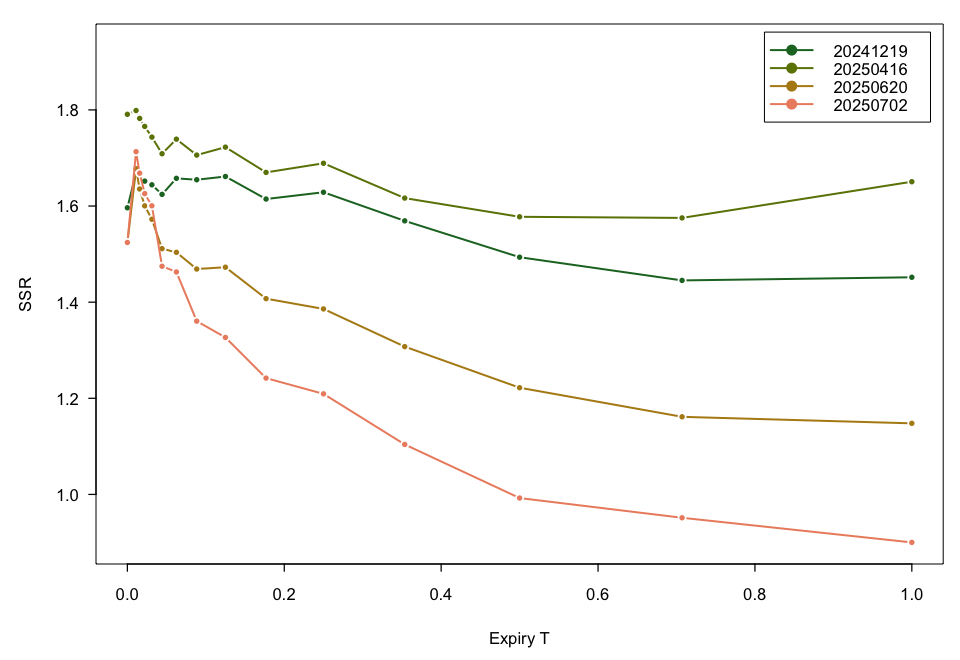

In [4]:
options(repr.plot.width = 8, repr.plot.height = 5.5)
par(
    bg = "white", mar = c(4, 4, 1, 0.7), ps = 10, cex = 1, lwd = 0.8,
    mgp = c(2.5, 0.7, 0), tcl = -0.3, xaxs = "i", yaxs = "i"
)
limits <- range(ssr$ssr)
plot(NA,
    xlim = c(-0.04, 1.04),
    ylim = c(limits[1] - 0.05 * diff(limits), limits[2] + 0.18),
    xlab = "Expiry T", ylab = "SSR", las = 1
)
for (i in seq_along(CALIB_DATES)) {
    d <- ssr[ssr$date == CALIB_DATES[i], ]
    lines(d$expiry, d$ssr, col = COLORS[i], lwd = 1.6, lend = "butt")
    points(d$expiry, d$ssr,
        pch = 21, bg = COLORS[i], col = "white",
        cex = 0.8, lwd = 1.4
    )
}
legend("topright",
    legend = CALIB_DATES, col = COLORS, lty = 1,
    lwd = 1.6, pch = 21, pt.bg = COLORS, bg = "white", inset = 0.015
)
